# Evaluating the final strategy over 2025

The final strategy is the Avellaneda–Stoikov market maker with the LightGBM adverse-selection premium, the queue-aware $k$, γ = 0.5 and a green-up threshold of 1 contract. It was backtested on every WIN race of 2025, twice: once as it is, and once with **diming** (`dime=True`), where a quote inside the spread goes at most one tick in front of the best price on its side.

**What was fitted where.** It matters which days the strategy has already seen:

| Period | Used for |
|---|---|
| January | estimating σ², $k$ and the markout horizon, and training the adverse-selection model |
| 1–14 February | tuning γ and the green-up threshold |
| **15 February – 31 December** | **nothing: this is the out-of-sample test** |

Results on January and early February flatter the strategy, so every headline number below is for the out-of-sample period, with the earlier part shown separately for reference.

**Which version we present.** The headline results are for the strategy **without diming**. Diming makes more in the backtest, but that gain rests on the backtest's most optimistic assumptions. A quote one tick in front of the best price is always first in line, and the backtest can't show anyone reacting to it. In a live market, other automated traders would often dime us straight back. So we treat diming as the best case and the plain strategy as the result we stand behind.

Each backtest uses the same engine settings: 0.2 s latency, the queue rules in `backtest/execution.py`, and 4% commission on each market's net winnings.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.lines import Line2D

# Project root = the folder that holds research/ (works whether this runs from evaluation/ or the root)
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "research" / "results").exists())
RUNS = {"no diming": ROOT / "research/results/final_2025_no_dime",
        "diming": ROOT / "research/results/final-year-dime"}
OUT_OF_SAMPLE_FROM = pd.Timestamp("2025-02-15").date()      # the first day nothing was fitted or tuned on
N_BOOT = 1000
rng = np.random.default_rng(42)

# Chart style: blue = no diming, orange = diming, greys for everything else
COLOURS = {"no diming": "#2a78d6", "diming": "#eb6834"}
GREY, LIGHT = "#898781", "#c3c2b7"
INK, INK_2 = "#0b0b0b", "#52514e"
%config InlineBackend.figure_format = "retina"
plt.rcParams.update({
    "figure.figsize": (8, 4.2), "figure.facecolor": "white", "axes.facecolor": "white",
    "font.family": "sans-serif", "font.sans-serif": ["Segoe UI", "Helvetica Neue", "Arial", "DejaVu Sans"],
    "font.size": 10, "text.color": INK, "axes.labelcolor": INK_2, "axes.labelpad": 6,
    "xtick.color": LIGHT, "xtick.labelcolor": INK_2, "ytick.labelcolor": INK_2, "ytick.major.size": 0,
    "axes.spines.top": False, "axes.spines.right": False, "axes.spines.left": False,
    "axes.edgecolor": LIGHT, "axes.linewidth": 0.8,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": "#e1e0d9", "grid.linewidth": 0.8,
    "lines.linewidth": 2, "lines.markersize": 7, "lines.markeredgewidth": 1.5, "lines.markeredgecolor": "white",
    "legend.frameon": False, "legend.fontsize": 9.5,
})


def titles(ax, title, subtitle, gap=10):
    # A bold headline that states the finding, then a smaller line saying what is plotted
    note = ax.annotate(subtitle, (0, 1), xycoords="axes fraction", xytext=(0, gap), textcoords="offset points",
                       fontsize=9.5, color=INK_2, va="bottom", linespacing=1.45)
    head = ax.set_title(title, loc="left", fontsize=12.5, fontweight="semibold",
                        pad=gap + 6 + 14 * (subtitle.count("\n") + 1))
    note.set_in_layout(False)
    head.set_in_layout(False)


def legend(ax, **kwargs):
    # A legend whose keys drop the white ring around markers (on a short key it makes a line look dashed)
    for key in ax.legend(**kwargs).legend_handles:
        if isinstance(key, Line2D):
            key.set_markeredgewidth(0)


missing = [name for name, folder in RUNS.items() if not (folder / "markets.csv").exists()]
RUNS = {name: folder for name, folder in RUNS.items() if name not in missing}
print("Runs found:", ", ".join(RUNS) or "none", "| still missing:", ", ".join(missing) or "none")

Runs found: no diming, diming | still missing: none


## Step 1: Loading the runs

From each backtest we take every race's profit after commission (`markets.csv`) and every fill (`fills.csv`). A race is dated by its first fill, on the Australian racing day it was run. Every race traded by either version goes into one table, with zero for a version that didn't trade it, so the two are compared on the same races.

In [2]:
def load_run(folder):
    markets = pd.read_csv(folder / "markets.csv", dtype={"market_id": str}).set_index("market_id")
    fills = pd.read_csv(folder / "fills.csv", dtype={"market_id": str})
    fills["time"] = pd.to_datetime(fills["publish_time"], format="ISO8601", utc=True)
    return markets, fills


runs = {name: load_run(folder) for name, folder in RUNS.items()}

first_fill = pd.concat([fills.groupby("market_id")["time"].min() for _, fills in runs.values()]).groupby(level=0).min()
race_time = first_fill.sort_values()
RACES = race_time.index                                         # in the order they were run
day = race_time.dt.tz_convert("Australia/Sydney").dt.date
local = race_time.dt.tz_convert("Australia/Sydney")
month = local.dt.strftime("%b").where(local.dt.year == 2025, "Dec")   # late races on 31 Dec fall on 1 Jan in Sydney
out_of_sample = (day >= OUT_OF_SAMPLE_FROM).to_numpy()
profit = pd.DataFrame({name: markets["net_pnl"].reindex(RACES, fill_value=0.0) for name, (markets, _) in runs.items()})
print(f"{len(RACES):,} races traded: {(~out_of_sample).sum():,} before 15 February, {out_of_sample.sum():,} from then on")

38,858 races traded: 4,625 before 15 February, 34,233 from then on


## Step 2: The headline numbers

For each version and period:

- **profit** after commission, with a 95% interval from resampling races (as in the earlier notebooks);
- **profit per race traded**, and the share of racing days that made money;
- **daily Sharpe ratio**: average daily profit divided by its standard deviation, and annualised (× √365, since there is racing every day);
- **largest drawdown**: the biggest fall in cumulative profit from a previous high;
- **fills**: how many of our quotes were filled.

In [3]:
def interval(values):
    ordered = np.sort(np.asarray(values))
    return ordered[int(0.025 * len(ordered))], ordered[int(0.975 * len(ordered)) - 1]


def headline(name, chosen):
    races = profit.loc[chosen, name]
    daily = races.groupby(day[chosen]).sum()
    cumulative = races.cumsum()
    draws = rng.multinomial(len(races), np.full(len(races), 1 / len(races)), size=N_BOOT)
    low, high = interval(draws @ races.to_numpy())
    markets, fills = runs[name]
    in_period = fills["market_id"].isin(races.index)
    return {"profit ($)": races.sum(), "95% CI low": low, "95% CI high": high,
            "races traded": int(markets.index.isin(races.index).sum()),
            "profit per race traded ($)": races.sum() / max(markets.index.isin(races.index).sum(), 1),
            "profitable days": f"{(daily > 0).sum()}/{len(daily)}",
            "daily Sharpe": daily.mean() / daily.std(), "annualised Sharpe": daily.mean() / daily.std() * np.sqrt(365),
            "largest drawdown ($)": (cumulative.cummax() - cumulative).max(),
            "quote fills": int(((fills["tag"] == "quote") & in_period).sum())}


PERIODS = {"out of sample (15 Feb – 31 Dec)": out_of_sample, "fitted and tuned on (Jan – 14 Feb)": ~out_of_sample}
summary = pd.DataFrame({(period, name): headline(name, chosen) for period, chosen in PERIODS.items() for name in RUNS}).T
summary.round(2)

profit ($)   95% CI low  \
out of sample (15 Feb – 31 Dec)    no diming  5118.412926  4875.180248   
                                   diming     6264.205278  6012.147542   
fitted and tuned on (Jan – 14 Feb) no diming   482.001802   397.773542   
                                   diming      561.192708   483.584994   

                                              95% CI high races traded  \
out of sample (15 Feb – 31 Dec)    no diming  5351.098292        34002   
                                   diming      6504.09215        33163   
fitted and tuned on (Jan – 14 Feb) no diming   572.376978         4604   
                                   diming       646.11104         4510   

                                             profit per race traded ($)  \
out of sample (15 Feb – 31 Dec)    no diming                   0.150533   
                                   diming                      0.188891   
fitted and tuned on (Jan – 14 Feb) no diming                   0.104692   
                                   diming                      0.124433   

                                             profitable days daily Sharpe  \
out of sample (15 Feb – 31 Dec)    no diming         300/320     1.305087   
                                   diming            308/320     1.530747   
fitted and tuned on (Jan – 14 Feb) no diming           41/45     1.357651   
                                   diming              42/45     1.473849   

                                             annualised Sharpe  \
out of sample (15 Feb – 31 Dec)    no diming          24.93365   
                                   diming            29.244877   
fitted and tuned on (Jan – 14 Feb) no diming         25.937893   
                                   diming            28.157846   

                                             largest drawdown ($) quote fills  
out of sample (15 Feb – 31 Dec)    no diming              65.4486      174881  
                                   diming               20.083366      150210  
fitted and tuned on (Jan – 14 Feb) no diming             16.28462       21594  
                                   diming                10.36426       19157

### Full statistics, out of sample

The same statistics as the backtester's own summary (`summary.txt`), restricted to 15 February – 31 December. Per-market figures are over the markets the strategy traded, in the order they were run.

- **t-stat:** mean market profit ÷ its standard error.
- **Wilcoxon test:** checks the same thing without assuming profits are normally distributed (markets with exactly zero profit are left out).
- **Return on stake:** net profit ÷ the total amount staked on every bet.

In [4]:
from scipy import stats


def money(value, sign=True):
    return f"{'+' if sign and value >= 0 else '−' if value < 0 else ''}${abs(value):,.2f}"


def p_value(value):
    return "< 1e-300" if value == 0 else f"{value:.3g}"            # below the smallest number a float can hold


def full_stats(name, chosen):
    markets, fills = runs[name]
    races = [race for race in RACES[chosen] if race in markets.index]      # traded by this version, in race order
    m = markets.loc[races]
    x = m["net_pnl"]
    sd = x.std(ddof=1)
    cumulative = x.cumsum()
    bets = pd.read_csv(RUNS[name] / "bets.csv", dtype={"market_id": str}, usecols=["market_id", "stake"])
    staked = bets.loc[bets["market_id"].isin(set(races)), "stake"].sum()
    f = fills[fills["market_id"].isin(set(races))]
    return {
        "markets traded": f"{len(x):,}",
        "gross profit": money(m["gross_pnl"].sum()),
        "commission (4%)": money(m["commission"].sum(), sign=False),
        "net profit": money(x.sum()),
        "mean / median per market": f"{money(x.mean())} / {money(x.median())}",
        "standard deviation per market": money(sd, sign=False),
        "t-stat (mean = 0)": f"{x.mean() / (sd / np.sqrt(len(x))):+.2f}",
        "p-value (t-test)": p_value(stats.ttest_1samp(x, 0).pvalue),
        "p-value (Wilcoxon)": p_value(stats.wilcoxon(x[x != 0]).pvalue),
        "markets profitable": f"{(x > 0).mean():.0%}",
        "worst / best market": f"{money(x.min())} / {money(x.max())}",
        "largest drawdown": money((cumulative.cummax() - cumulative).max(), sign=False),
        "total staked": money(staked, sign=False),
        "return on stake": f"{x.sum() / staked:+.3%}",
        "fills: quote / green-up": f"{(f['tag'] == 'quote').sum():,} / {(f['tag'] == 'greenup').sum():,}",
        "largest position (contracts)": f"{f['q_after'].abs().max():.1f}",
    }


pd.DataFrame({name: full_stats(name, out_of_sample) for name in RUNS}).rename_axis("out of sample (15 Feb – 31 Dec)")

,no diming,diming
out of sample (15 Feb – 31 Dec),,
markets traded,"34,002","33,163"
gross profit,"+$5,543.07","+$6,696.65"
commission (4%),$424.65,$432.45
net profit,"+$5,118.41","+$6,264.21"
mean / median per market,+$0.15 / +$0.12,+$0.19 / +$0.12
standard deviation per market,$0.74,$0.67
t-stat (mean = 0),+37.44,+51.28
p-value (t-test),1.21e-300,< 1e-300
p-value (Wilcoxon),< 1e-300,< 1e-300


**What this shows (the headline strategy, without diming)**

- **The strategy makes money out of sample, and clearly so.** From 15 February to 31 December it made **$5,118 after commission (95% CI $4,875–5,351)** over 34,002 races, about 15 cents a race (median 12 cents, 62% of races profitable). The interval is nowhere near zero: the t-stat is +37.4, and both the t-test and the Wilcoxon test put the chance of this happening with no real edge below 10⁻³⁰⁰. The return on everything staked is +0.86%.
- **It holds up better than on the data it was fitted and tuned on.** Per race, it made more out of sample (15.1 cents) than in January and early February (10.5 cents). So the result isn't an artefact of tuning on the same days.
- **It's very steady.** 300 of 320 out-of-sample days were profitable, and the largest drawdown was $65. Each race risks little: positions are small, and flattened at $T$.
- **The Sharpe ratio is unrealistically high, as usual for a market-making backtest.** Daily profit barely varies, so the annualised Sharpe ratio is about 25. A live strategy would face things the backtest can't model: other traders reacting to our orders, competition for queue position, and minimum stakes. So read it as "consistent", not as a forecast.

## Step 3: Profit through the year

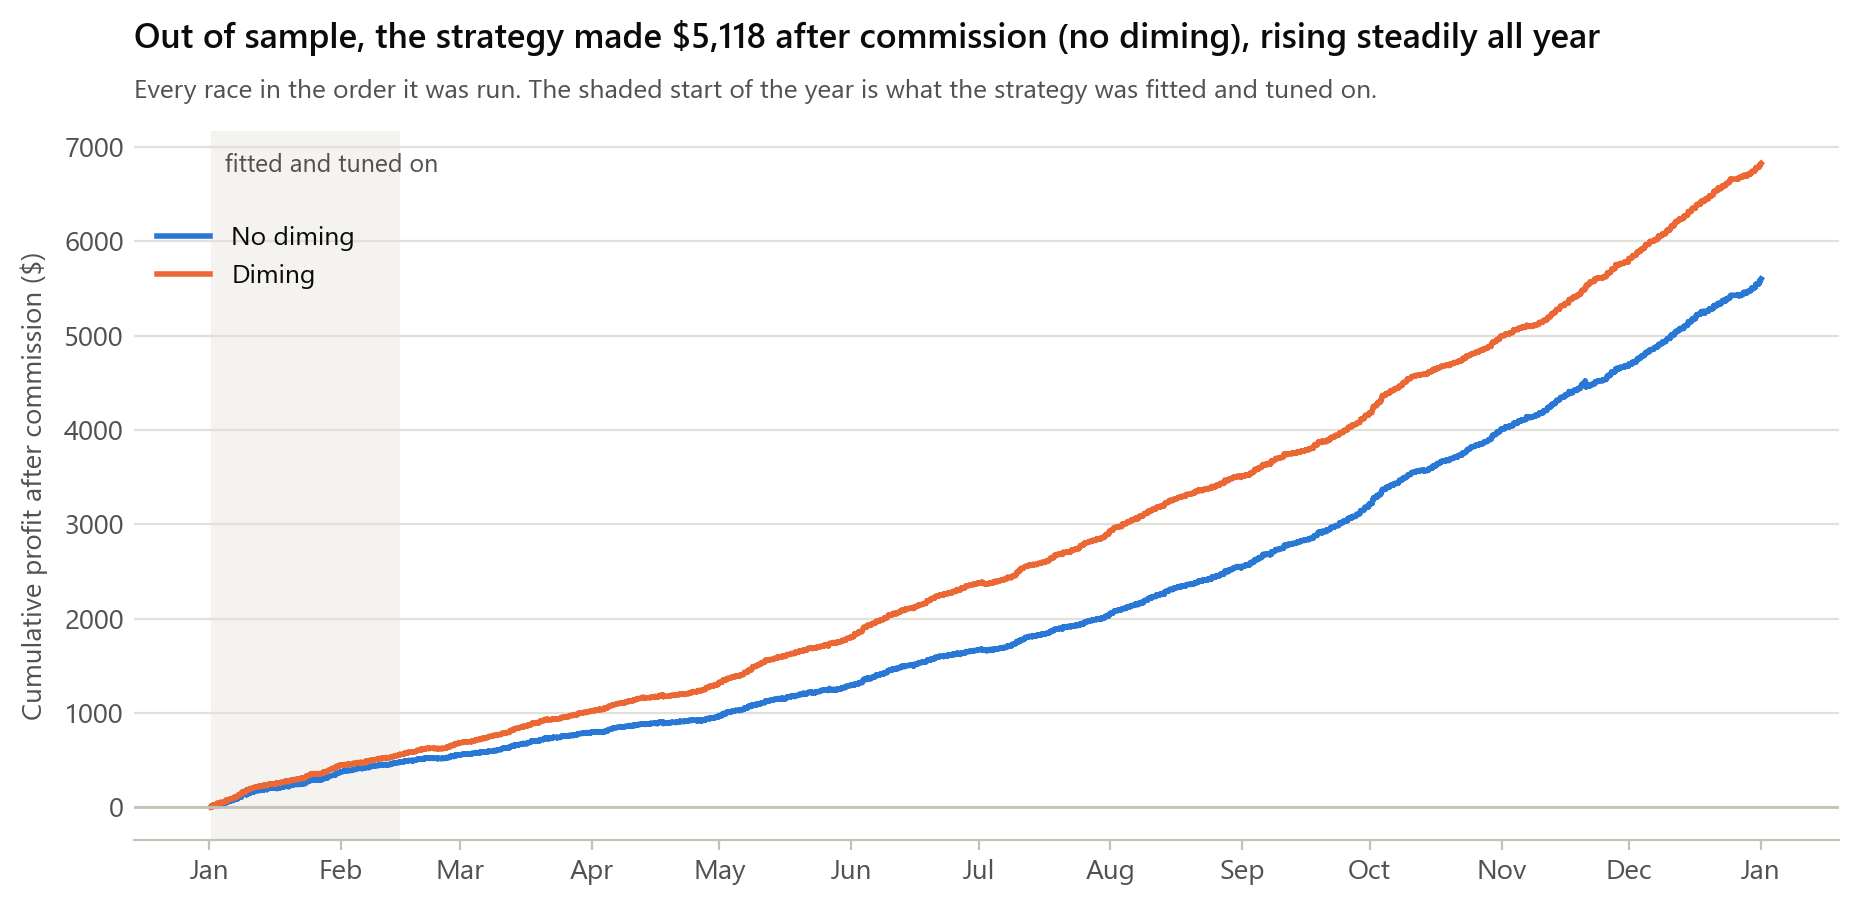

In [5]:
import matplotlib.dates as mdates

when = race_time.dt.tz_convert("Australia/Sydney").dt.tz_localize(None)       # local racing time
fig, ax = plt.subplots(figsize=(11, 4.6))
start = when.iloc[np.argmax(out_of_sample)] if out_of_sample.any() else when.iloc[-1]
ax.axvspan(when.iloc[0], start, color="#f4f3ef", lw=0, zorder=0)
ax.text(when.iloc[0], 0.97, "  fitted and tuned on", transform=ax.get_xaxis_transform(), va="top", fontsize=9,
        color=INK_2)
for name in RUNS:
    ax.plot(when.to_numpy(), profit[name].cumsum().to_numpy(), color=COLOURS[name], label=name.capitalize())
ax.axhline(0, color=LIGHT, lw=1)
ax.set(ylabel="Cumulative profit after commission ($)")
ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
legend(ax, loc="upper left", bbox_to_anchor=(0, 0.9))
first = next(iter(RUNS))
titles(ax, f"Out of sample, the strategy made ${profit.loc[out_of_sample, first].sum():,.0f} after commission "
       f"({first}), rising steadily all year",
       "Every race in the order it was run. The shaded start of the year is what the strategy was fitted and tuned on.")
plt.show()

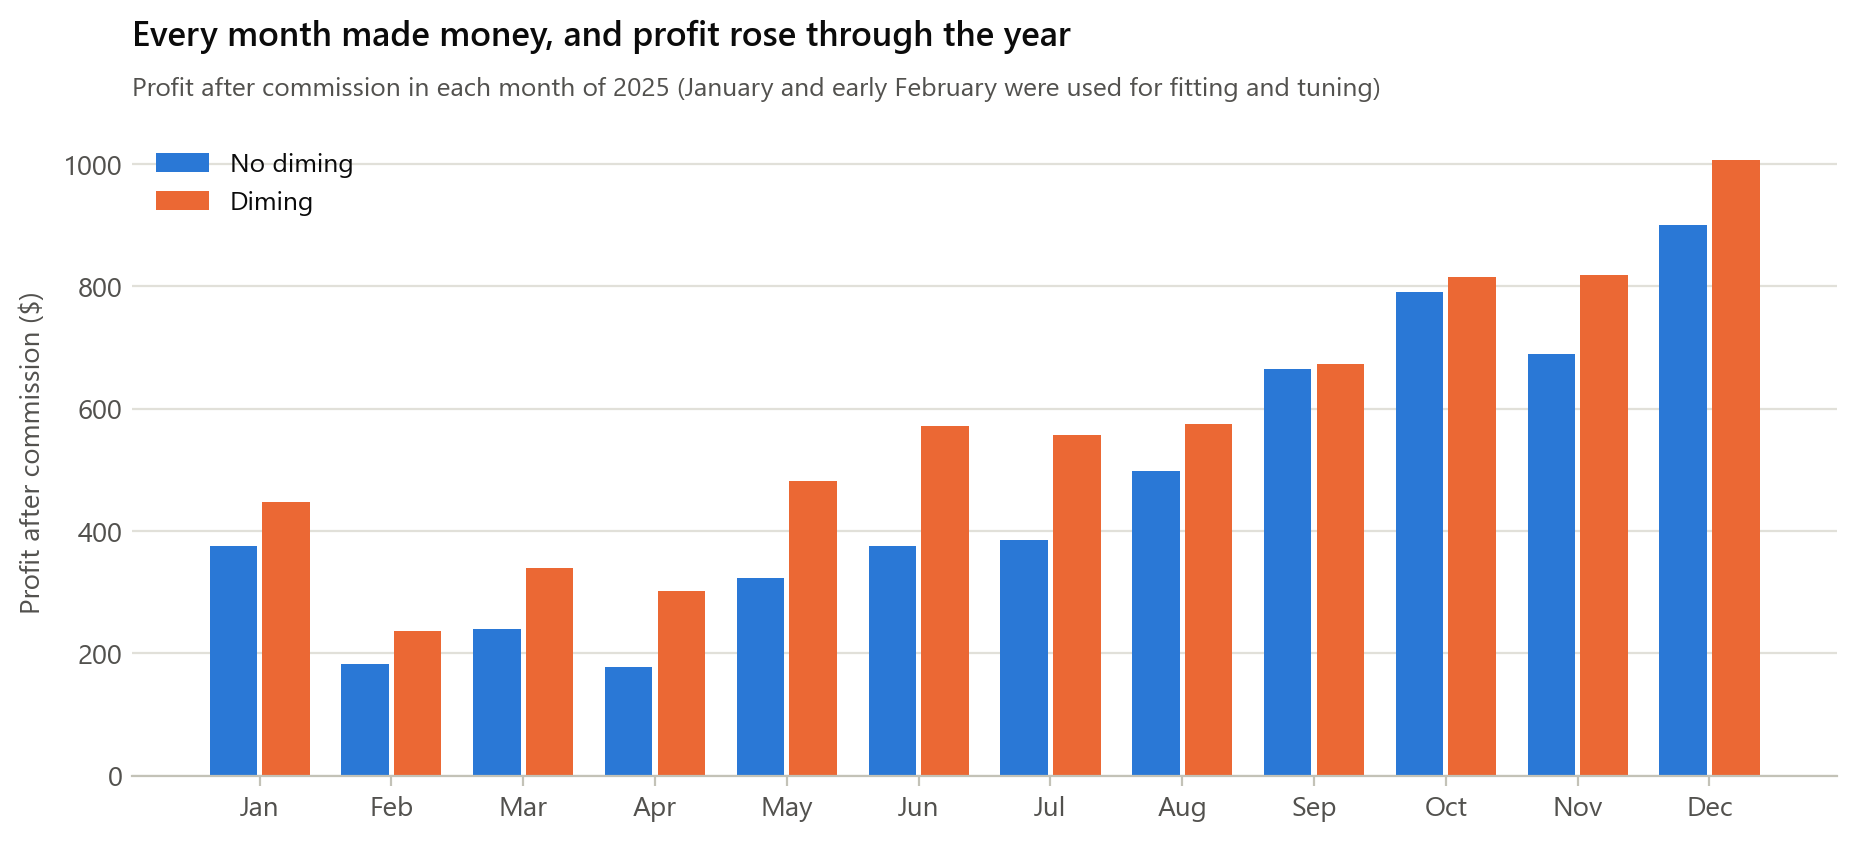

no diming                                                            \
      races traded profit ($) quote fills fills per race profit per race ($)   
month                                                                          
Jan           3272    374.713       15738          4.810               0.115   
Feb           2776    181.885       12141          4.374               0.066   
Mar           3033    239.698       13934          4.594               0.079   
Apr           2895    177.263       11685          4.036               0.061   
May           3286    322.285       15890          4.836               0.098   
Jun           3256    375.919       16436          5.048               0.115   
Jul           3279    384.521       16227          4.949               0.117   
Aug           3256    498.344       15900          4.883               0.153   
Sep           3332    665.025       16980          5.096               0.200   
Oct           3428    791.010       17616          5.139               0.231   
Nov           3355    689.136       19690          5.869               0.205   
Dec           3438    900.615       24238          7.050               0.262   

                                diming                                        \
      profit per fill ($) races traded profit ($) quote fills fills per race   
month                                                                          
Jan                 0.024         3220    447.403       13997          4.347   
Feb                 0.015         2704    236.388       10696          3.956   
Mar                 0.017         2965    340.153       12468          4.205   
Apr                 0.015         2819    301.841       10392          3.686   
May                 0.020         3202    480.996       13955          4.358   
Jun                 0.023         3191    571.393       14371          4.504   
Jul                 0.024         3220    556.799       14555          4.520   
Aug                 0.031         3192    575.510       13972          4.377   
Sep                 0.039         3232    672.419       14367          4.445   
Oct                 0.045         3298    815.704       14511          4.400   
Nov                 0.035         3266    819.371       16190          4.957   
Dec                 0.037         3364   1007.421       19893          5.913   

                                               
      profit per race ($) profit per fill ($)  
month                                          
Jan                 0.139               0.032  
Feb                 0.087               0.022  
Mar                 0.115               0.027  
Apr                 0.107               0.029  
May                 0.150               0.034  
Jun                 0.179               0.040  
Jul                 0.173               0.038  
Aug                 0.180               0.041  
Sep                 0.208               0.047  
Oct                 0.247               0.056  
Nov                 0.251               0.051  
Dec                 0.299               0.051

In [6]:
MONTHS = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
monthly = profit.groupby(month.rename("month")).sum().reindex([m for m in MONTHS if m in set(month)])

fig, ax = plt.subplots(figsize=(11, 4.2))
width = 0.8 / len(RUNS)
for i, name in enumerate(RUNS):
    ax.bar(np.arange(len(monthly)) + (i - (len(RUNS) - 1) / 2) * width, monthly[name], width=width * 0.9,
           color=COLOURS[name], label=name.capitalize())
ax.axhline(0, color=INK_2, lw=1)
ax.set_xticks(np.arange(len(monthly)), monthly.index)
ax.set_axisbelow(True)
ax.set(ylabel="Profit after commission ($)")
legend(ax, loc="upper left")
titles(ax, "Every month made money, and profit rose through the year",
       "Profit after commission in each month of 2025 (January and early February were used for fitting and tuning)")
plt.show()

# What changed: how many races and fills, and how much each one made
breakdown = {}
for name, (markets, fills) in runs.items():
    quote_fills = fills[fills["tag"] == "quote"]
    traded = month.reindex(markets.index.intersection(RACES))
    breakdown[name] = pd.DataFrame({
        "races traded": traded.value_counts(),
        "profit ($)": profit[name].groupby(month).sum(),
        "quote fills": quote_fills.groupby(quote_fills["market_id"].map(month)).size(),
    }).reindex(monthly.index)
    breakdown[name]["fills per race"] = breakdown[name]["quote fills"] / breakdown[name]["races traded"]
    breakdown[name]["profit per race ($)"] = breakdown[name]["profit ($)"] / breakdown[name]["races traded"]
    breakdown[name]["profit per fill ($)"] = breakdown[name]["profit ($)"] / breakdown[name]["quote fills"]
pd.concat(breakdown, axis=1).rename_axis("month").round(3)

The number of races is steady, at about 3,300 a month. The growth comes from what each race is worth: profit per quote fill more than doubled, from about 1.5 cents in February–April to 3.5–4.5 cents from September on. Fills per race also jumped in November and December (5.9 and 7.0, against about 5 before). The market changed during the year in a way that suits the strategy, perhaps wider spreads or more uninformed money. The profit breakdown below should show which.

## Step 4: Does diming help?

Diming changes where some quotes sit, so the two versions trade many of the same races. The fair comparison is race by race: for each race, profit with diming minus profit without, resampled by race for a paired 95% interval.

In [7]:
if len(RUNS) == 2:
    difference = (profit["diming"] - profit["no diming"])[out_of_sample]
    draws = rng.multinomial(len(difference), np.full(len(difference), 1 / len(difference)), size=N_BOOT)
    low, high = interval(draws @ difference.to_numpy())
    daily_difference = difference.groupby(day[out_of_sample]).sum()
    print(f"Out of sample, diming changes profit by ${difference.sum():+.2f} (95% CI {low:+.2f} to {high:+.2f}); "
          f"it's ahead on {(daily_difference > 0).sum()} of {len(daily_difference)} days")
else:
    print("Needs both runs")

Out of sample, diming changes profit by $+1145.79 (95% CI +942.38 to +1334.17); it's ahead on 240 of 320 days


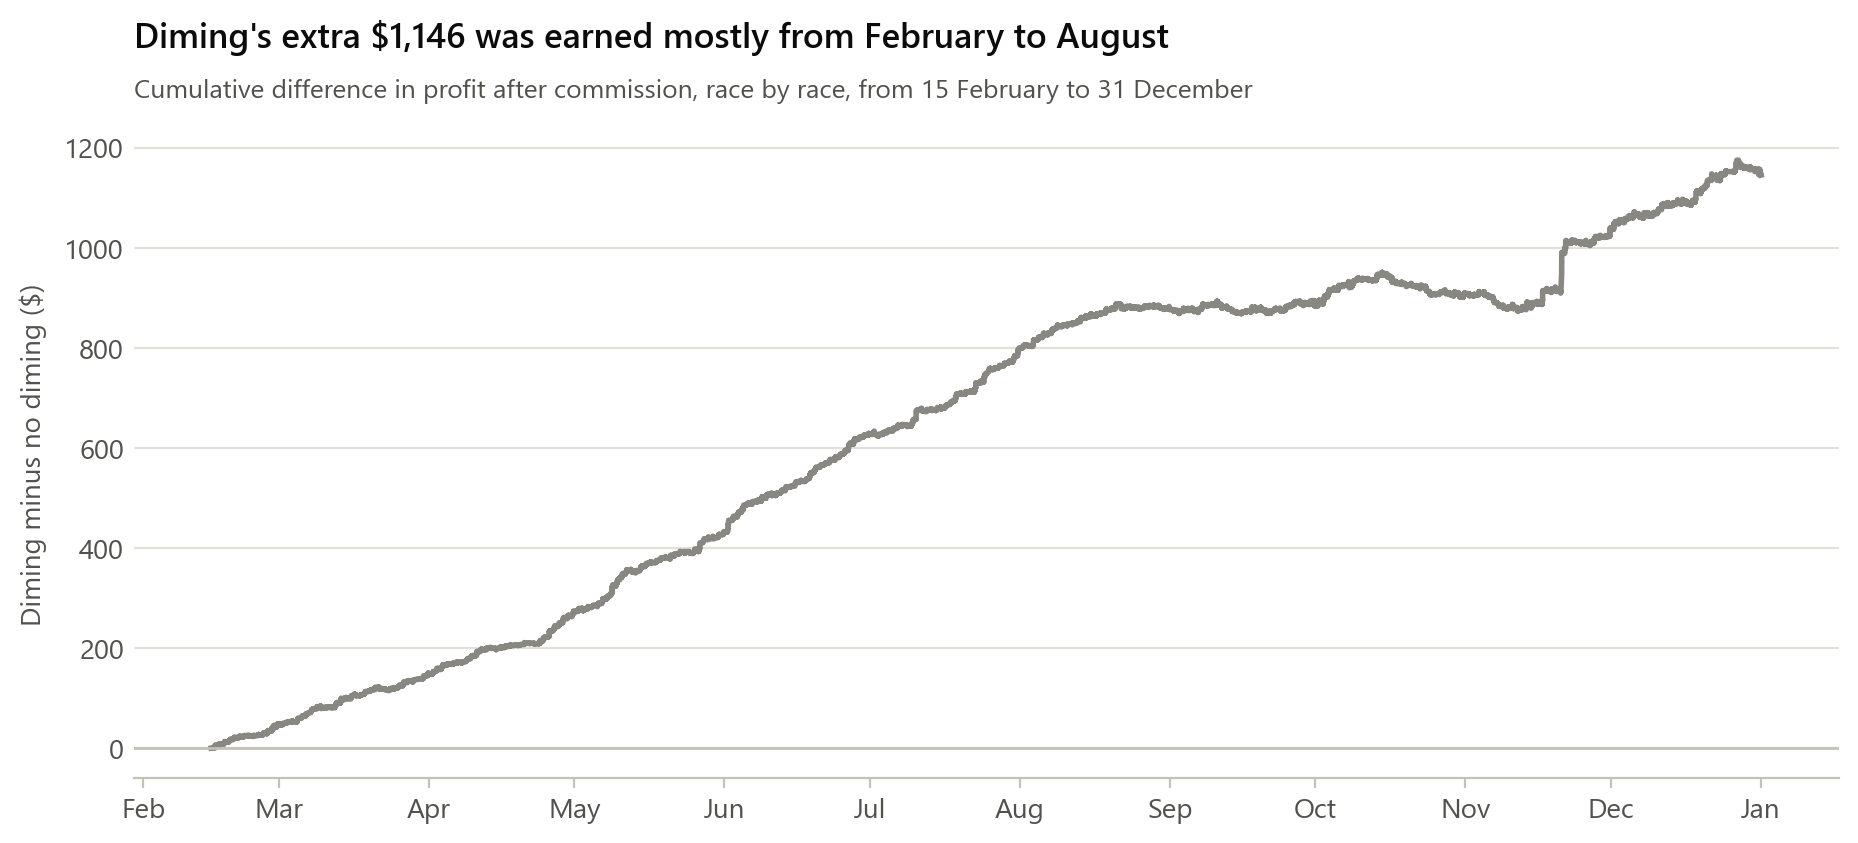

In [8]:
if len(RUNS) == 2:
    when_out = when[out_of_sample]
    fig, ax = plt.subplots(figsize=(11, 4.2))
    ax.plot(when_out.to_numpy(), difference.cumsum().to_numpy(), color=GREY)
    ax.axhline(0, color=LIGHT, lw=1)
    ax.xaxis.set_major_locator(mdates.MonthLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
    ax.set(ylabel="Diming minus no diming ($)")
    titles(ax, f"Diming's extra ${difference.sum():,.0f} was earned mostly from February to August",
           "Cumulative difference in profit after commission, race by race, from 15 February to 31 December")
    plt.show()

**What this shows**

- **Diming makes more, steadily.** Out of sample it adds about $1,150 (paired 95% CI $940–1,330), roughly 22% more than the plain strategy, and it's ahead on 240 of 320 days. The gap grows steadily from February to August, then stays flat from September to mid-November: late in the year, as the market became more profitable for both versions, diming's edge stopped growing. The jump around 20 November is a single race, the one where the plain strategy ended up holding 318 contracts (below).
- **It makes more from fewer fills.** Diming has about 14% fewer quote fills, but each one is worth more: 4–5 cents a fill late in the year, against 3.5–4.5 without it. Quotes that would otherwise sit several ticks inside a wide spread now sit one tick in front of the best price. That gives away less of the spread, and they're picked off less often.
- **It's also less risky.** Its worst race lost $15.50 (against $36.21), the largest drawdown was $20 (against $65), and positions never went past the cap. Without diming, a deep-inside quote can be filled at a much better price than requested when a runner's price collapses within the latency, and the stake then buys far more contracts than intended. That's where the 318-contract position came from.
- **Why it's not the headline anyway.** All of this assumes a quote one tick in front is always first in line and that nobody responds to it. That's the case where the backtest is least realistic, so we present the plain strategy as our result, and diming as the upside if those queue positions held up in practice.

## Step 5: Volume and efficiency

Profit alone doesn't show how hard the strategy works for it. Here we look at how much it trades and how much it makes per dollar traded, all out of sample.

- **Volume** is the total stake matched, the measure Betfair itself uses. We split it into the quotes we were filled on and the bets we placed to flatten our positions at $T$.
- **Profit per $100 traded** is profit after commission ÷ volume × 100.

`bets.csv` and `fills.csv` list the same fills in the same order, so each bet can be labelled as a quote or a green-up.

In [9]:
traded = {}
for name, folder in RUNS.items():
    bets = pd.read_csv(folder / "bets.csv", dtype={"market_id": str},
                       usecols=["market_id", "selection_id", "price", "stake", "gross_pnl"])
    fills = runs[name][1]
    assert (bets["market_id"].to_numpy() == fills["market_id"].to_numpy()).all()   # same fills, same order
    bets["tag"] = fills["tag"].to_numpy()
    bets = bets[bets["market_id"].isin(set(RACES[out_of_sample]))]
    bets["month"] = bets["market_id"].map(month)
    traded[name] = bets

volume_summary = pd.DataFrame({name: {
    "volume traded ($)": b["stake"].sum(),
    "  from quotes ($)": b.loc[b["tag"] == "quote", "stake"].sum(),
    "  from green-ups ($)": b.loc[b["tag"] == "greenup", "stake"].sum(),
    "contracts traded": (b["stake"] * b["price"]).sum(),
    "average bet ($)": b["stake"].mean(),
    "profit per $100 traded ($)": 100 * profit.loc[out_of_sample, name].sum() / b["stake"].sum(),
} for name, b in traded.items()})
volume_summary.rename_axis("out of sample (15 Feb – 31 Dec)").round(2)

,no diming,diming
out of sample (15 Feb – 31 Dec),,
volume traded ($),597591.70,535652.16
from quotes ($),432981.55,377868.18
from green-ups ($),164610.15,157783.98
contracts traded,1831751.73,1629224.53
average bet ($),2.64,2.69
profit per $100 traded ($),0.86,1.17


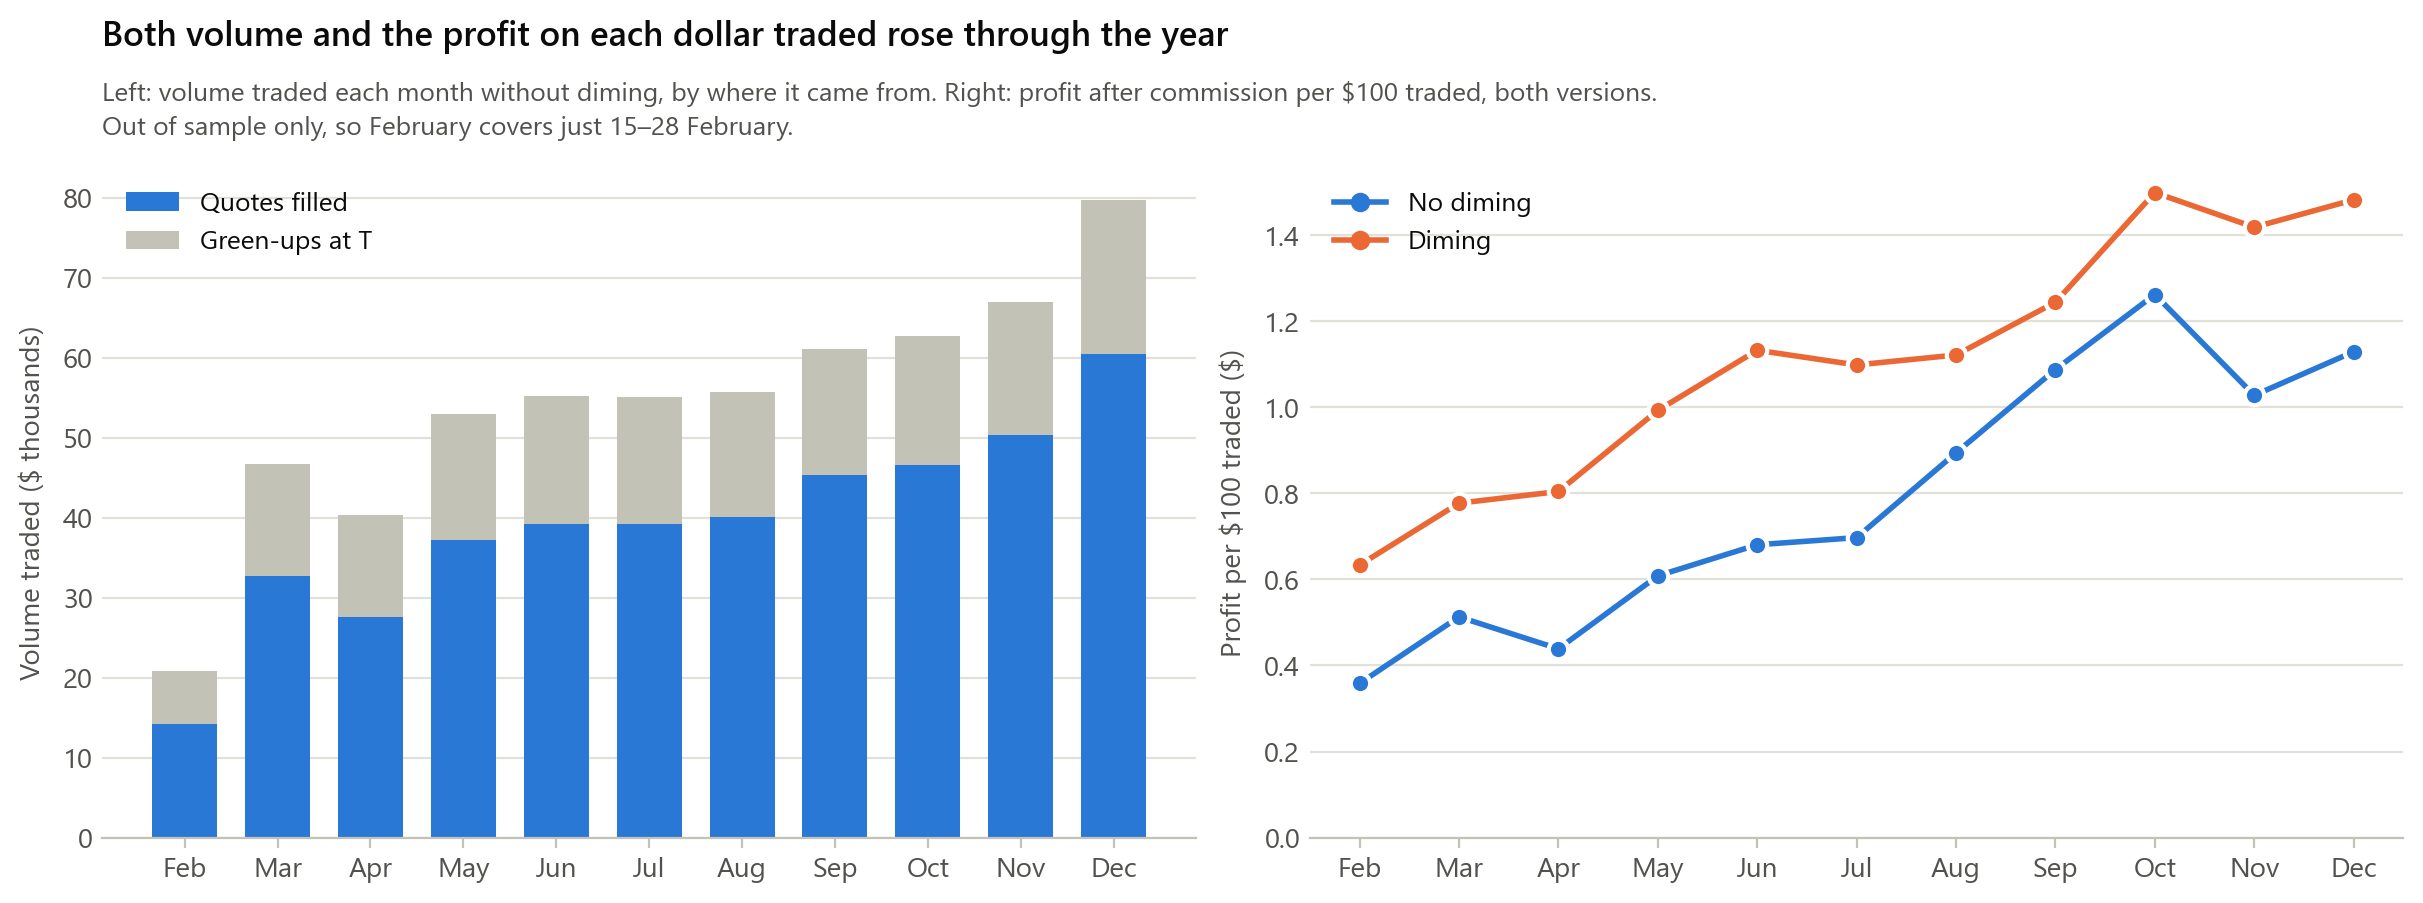

In [10]:
OUT_MONTHS = [m for m in MONTHS if m in set(month[out_of_sample])]
headline_name = next(iter(RUNS))
by_month = traded[headline_name].groupby(["month", "tag"])["stake"].sum().unstack("tag").reindex(OUT_MONTHS) / 1000
efficiency = pd.DataFrame({name: 100 * profit.loc[out_of_sample, name].groupby(month[out_of_sample]).sum()
                           / b.groupby("month")["stake"].sum() for name, b in traded.items()}).reindex(OUT_MONTHS)

fig, (left, right) = plt.subplots(1, 2, figsize=(12, 4.4), layout="constrained")
x = np.arange(len(OUT_MONTHS))
left.bar(x, by_month["quote"], width=0.7, color=COLOURS[headline_name], label="Quotes filled")
left.bar(x, by_month["greenup"], width=0.7, bottom=by_month["quote"], color=LIGHT, label="Green-ups at T")
left.set_xticks(x, OUT_MONTHS)
left.set_axisbelow(True)
left.set(ylabel="Volume traded ($ thousands)")
legend(left, loc="upper left")
for name in RUNS:
    right.plot(x, efficiency[name], "-o", color=COLOURS[name], label=name.capitalize())
right.set_xticks(x, OUT_MONTHS)
right.set(ylabel=r"Profit per \$100 traded (\$)", ylim=(0, None))
legend(right, loc="upper left")
titles(left, "Both volume and the profit on each dollar traded rose through the year",
       "Left: volume traded each month without diming, by where it came from. Right: profit after commission per "
       r"\$100 traded, both versions." "\nOut of sample only, so February covers just 15–28 February.")
plt.show()

**What this shows**

- **The strategy traded about $598,000 out of sample** (without diming), or about 1.8 million contracts in bets averaging $2.64. Roughly 28% of that volume ($165,000) is green-up: the cost of flattening positions at $T$, crossing the spread to do it.
- **It makes 86 cents per $100 traded** after commission. That's a thin margin, typical of market making: the edge comes from doing it many times, not from any single trade. Diming makes $1.17 per $100, on 10% less volume.
- **Both volume and the margin grew through the year.** Monthly volume roughly doubled from April to December. Profit per $100 rose from about 40–50 cents in February–April to over $1 from September. So the rising monthly profit is partly more trading and mostly better trading: each dollar traded earned about two and a half times as much late in the year.

## Step 6: Which runners the profit comes from

For each runner in each race we add up all our bets on it (quotes and green-ups), so its position nets out. Each runner is placed in a band by the average price of our quote fills on it. This is before commission, which Betfair charges per market rather than per runner.

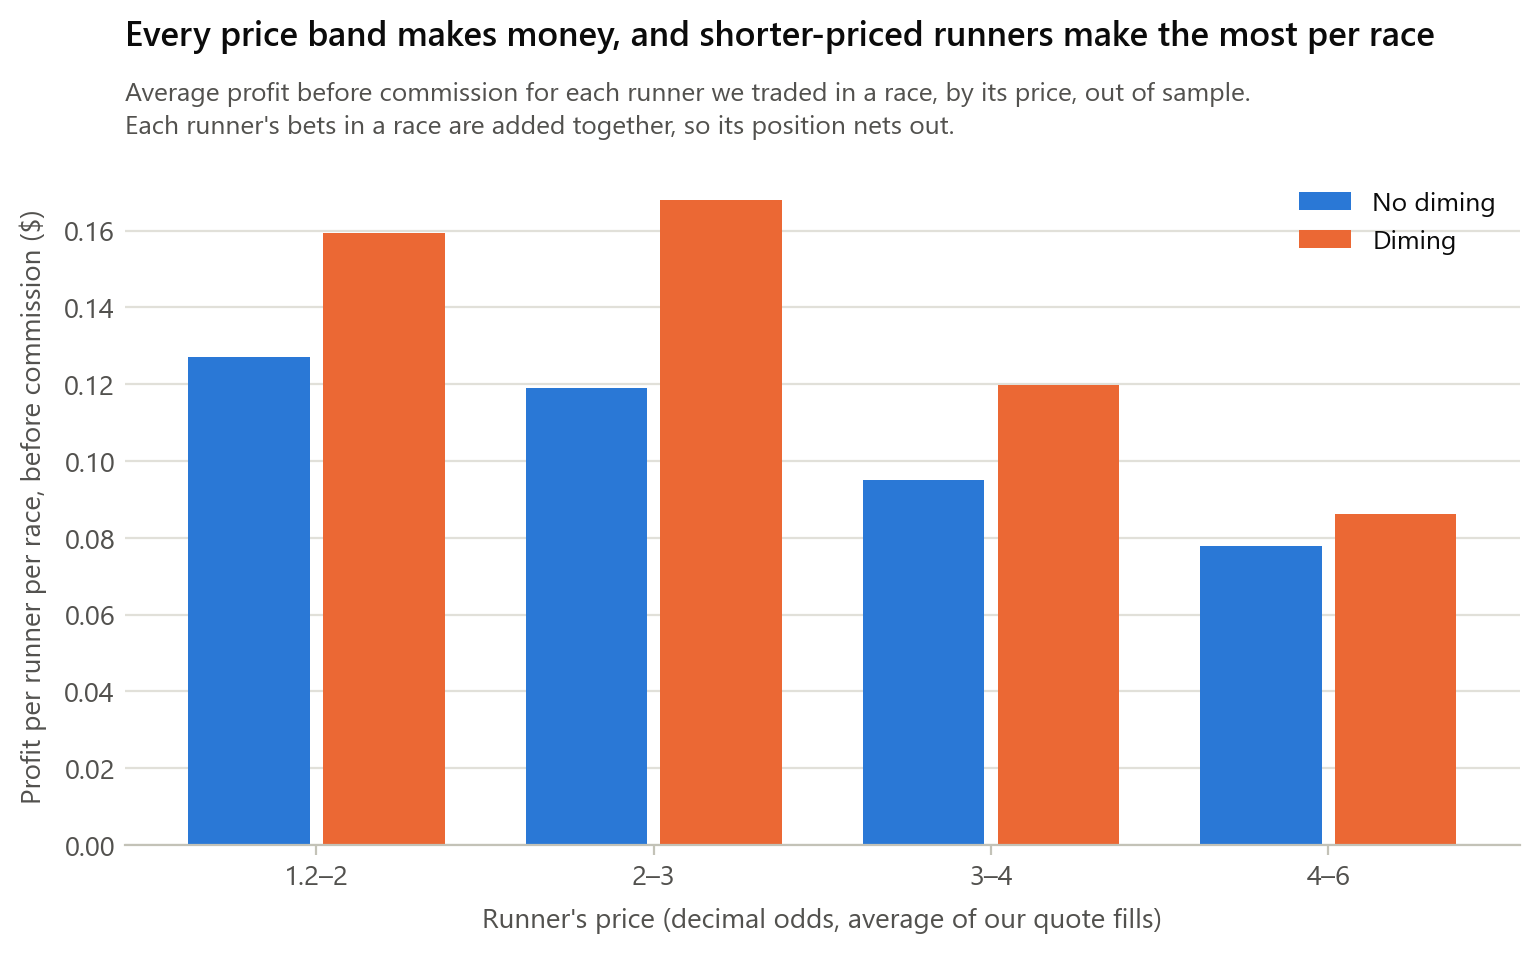

no diming                                      diming  \
      profit ($) per runner-race ($) runner-races profit ($)   
band                                                           
1.2–2    914.595               0.127         7195   1118.970   
2–3     1516.317               0.119        12754   2086.683   
3–4     1339.959               0.095        14111   1602.277   
4–6     1814.304               0.078        23339   1865.988   

                                        
      per runner-race ($) runner-races  
band                                    
1.2–2               0.159         7019  
2–3                 0.168        12416  
3–4                 0.120        13372  
4–6                 0.086        21629

In [11]:
BANDS = [1.2, 2, 3, 4, 6.01]
BAND_NAMES = ["1.2–2", "2–3", "3–4", "4–6"]
per_runner = {}
for name, b in traded.items():
    runner = b.groupby(["market_id", "selection_id"])
    quotes = b[b["tag"] == "quote"].groupby(["market_id", "selection_id"])["price"].mean()
    table = pd.DataFrame({"profit": runner["gross_pnl"].sum(), "odds": quotes}).dropna()
    table["band"] = pd.cut(table["odds"], BANDS, labels=BAND_NAMES)
    per_runner[name] = table.groupby("band", observed=False)["profit"].agg(["sum", "mean", "size"])

fig, ax = plt.subplots(figsize=(9, 4.4))
x = np.arange(len(BAND_NAMES))
width = 0.8 / len(RUNS)
for i, name in enumerate(RUNS):
    ax.bar(x + (i - (len(RUNS) - 1) / 2) * width, per_runner[name]["mean"], width=width * 0.9, color=COLOURS[name],
           label=name.capitalize())
ax.axhline(0, color=INK_2, lw=1)
ax.set_xticks(x, BAND_NAMES)
ax.set_axisbelow(True)
ax.set(xlabel="Runner's price (decimal odds, average of our quote fills)",
       ylabel="Profit per runner per race, before commission ($)")
legend(ax, loc="upper right")
titles(ax, "Every price band makes money, and shorter-priced runners make the most per race",
       "Average profit before commission for each runner we traded in a race, by its price, out of sample.\n"
       "Each runner's bets in a race are added together, so its position nets out.")
plt.show()

pd.concat({name: t.rename(columns={"sum": "profit ($)", "mean": "per runner-race ($)", "size": "runner-races"})
           for name, t in per_runner.items()}, axis=1).round(3)

**What this shows**

- **Every price band is profitable**, so the result doesn't hang on one kind of runner.
- **Shorter-priced runners make the most per race:** about 12–13 cents per runner per race for runners priced 1.2–3, against 8 cents for 4–6 (no diming). A likely reason is that more money trades on shorter-priced runners, so their prices are steadier and our fills there are less often followed by a sharp move.
- **Longer-priced runners still add the most in total**, because there are far more of them in the 1.2–6.0 range: 23,000 runner-races priced 4–6 against 7,000 priced 1.2–2.
- **Diming adds the most on runners priced 1.2–3** (about 4–5 cents per runner per race), where spreads are tight and being one tick in front matters most.